<a href="https://colab.research.google.com/github/ShiX27/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

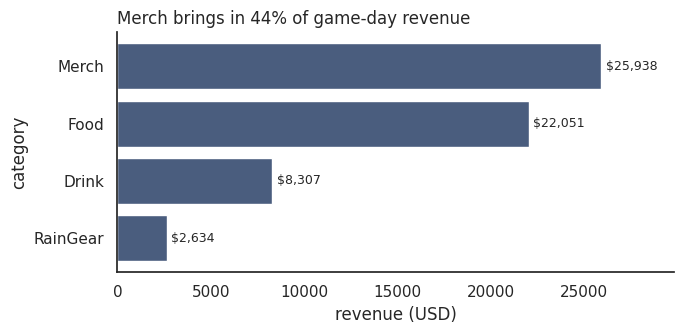

In [2]:
by_cat = df.groupby('category')['revenue'].sum()
s = by_cat.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(s.index, s.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in s.values], padding=3, fontsize=9)
ax.set_xlim(0, s.max() * 1.15)                             # room at the end for the labels
finish(ax, f'{s.idxmax()} brings in {s.max() / s.sum():.0%} of game-day revenue', xlabel='revenue (USD)', ylabel='category')
plt.show()

**Caption:** Merch and Food generate the most game-day revenue, making them key priorities for inventory and budget planning.

**Code Explanation:** First, I grouped the `df` DataFrame by `category`, calculated the total revenue using `.sum()`, and stored the result in `by_cat`. Second, I sorted `by_cat` by total revenue in ascending order using `.sort_values()`. Third, I created a horizontal bar chart and displayed the revenue values at the end of each bar. I also extended the x-axis limit to leave enough space for the revenue labels. Finally, I used `finish()` to add a title highlighting the category with the highest share of total revenue and label the x-axis as revenue (USD).

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

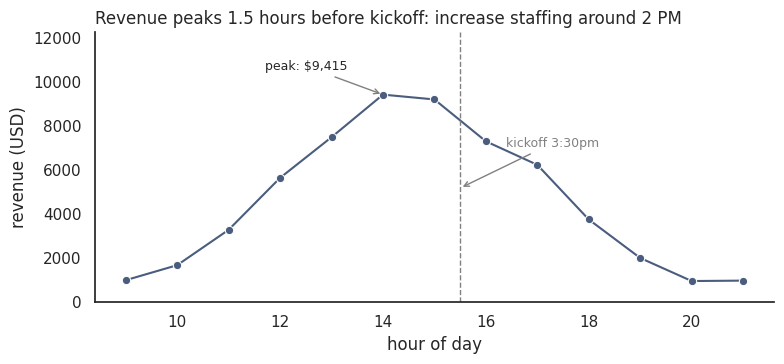

In [3]:
per_hour = df.groupby('hour')['revenue'].sum().reset_index()
peak_hour = per_hour.loc[per_hour['revenue'].idxmax(), 'hour']
peak_revenue = per_hour['revenue'].max()
hours_before = 15.5 - peak_hour

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.lineplot(data=per_hour, x ='hour', y='revenue', marker='o', color=BLUE, ax=ax)

ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, peak_revenue * 0.55), xytext=(16.4, peak_revenue * 0.75),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9, color='gray')

ax.annotate(f'peak: ${peak_revenue:,.0f}', xy=(peak_hour, peak_revenue), xytext=(peak_hour - 1.5, peak_revenue * 1.12), ha='center',
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9)

ax.set_ylim(0, peak_revenue * 1.3)
finish(ax, f'Revenue peaks {hours_before:g} hours before kickoff: increase staffing around {peak_hour - 12:g} PM',
       xlabel='hour of day', ylabel='revenue (USD)')
plt.show()

**Caption:** Hourly revenue trends help identify peak hours and determine when to assign additional staff to handle higher customer demand on game days.

**Code Explanation:** First, I grouped the `df` DataFrame by `hour`, calculated the total revenue using `.sum()`, used `.reset_index()` to convert the result into a DataFrame, and stored it in `per_hour`. Second, I identified the hour with the highest revenue using `.idxmax()` and stored the result in `peak_hour`. I also calculated the peak revenue using `.max()`, stored it in `peak_revenue`, and determined how many hours before the 3:30pm kickoff the peak occurred. Third, I created a line chart using seaborn to show how revenue changes throughout the day. I also added a vertical dashed line to mark the 3:30pm kickoff and used `.annotate()` to label the kickoff time and peak revenue with arrows. Fourth, I adjusted the y-axis limit to leave enough space for the annotations. Finally, I used `finish()` to add a title highlighting the peak revenue time and its staffing implication, along with labels for both axes.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

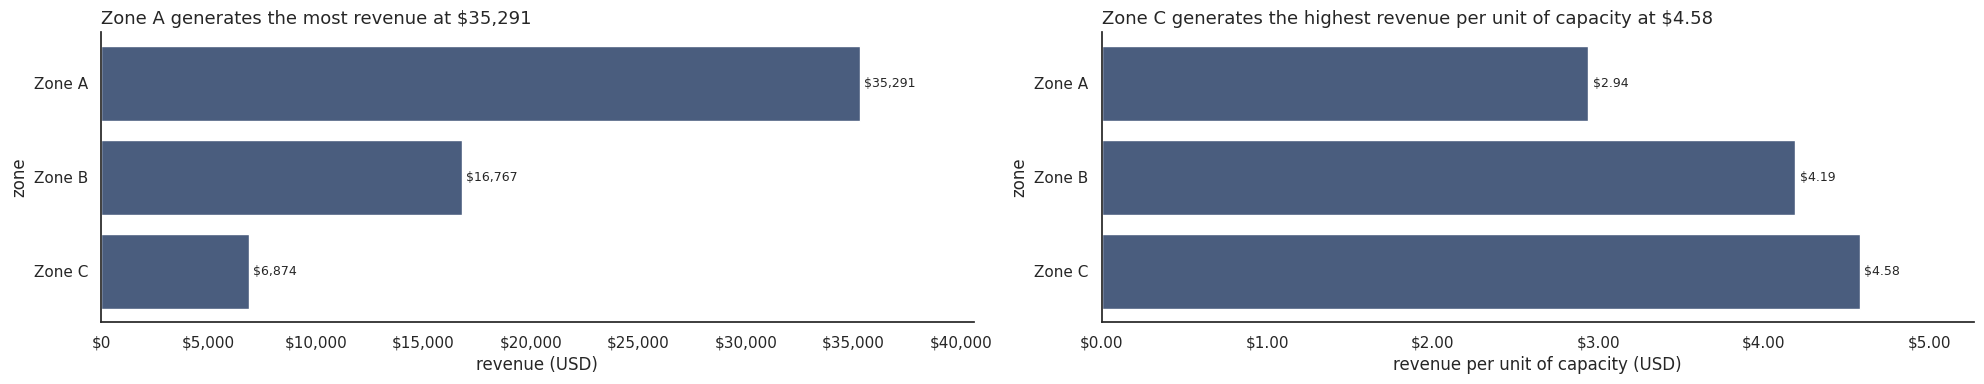

In [4]:
from matplotlib.ticker import FuncFormatter

zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity
by_zone = df.groupby('zone')['revenue'].sum()
revenue_per_capacity = by_zone / pd.Series(zone_capacity)

zone = by_zone.sort_values()
normalized = revenue_per_capacity.reindex(zone.index)

# Left panel: Raw revenue
fig, axes = plt.subplots(1, 2, figsize=(20, 4))
bar1 = axes[0].barh('Zone ' + zone.index, zone.values, color=BLUE)
axes[0].bar_label(bar1, labels=[f'${v:,.0f}' for v in zone.values], padding=3, fontsize=9)
axes[0].set_xlim(0, zone.max() * 1.15)
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.0f}'))
finish(axes[0], f'Zone {zone.idxmax()} generates the most revenue at ${zone.max():,.0f}',
       xlabel='revenue (USD)', ylabel='zone', fontsize=13)

# Right panel: Revenue per unit of capacity
bar2 = axes[1].barh('Zone ' + normalized.index, normalized.values, color=BLUE)
axes[1].bar_label(bar2, labels=[f'${v:.2f}' for v in normalized.values], padding=3, fontsize=9)
axes[1].set_xlim(0, normalized.max() * 1.15)
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:.2f}'))
finish(axes[1], f'Zone {normalized.idxmax()} generates the highest revenue per unit of capacity at ${normalized.max():.2f}',
       xlabel='revenue per unit of capacity (USD)', ylabel='zone', fontsize=13)

plt.tight_layout()
plt.show()

**Caption:** Comparing total revenue per zone and revenue per unit of capacity helps managers compare sales performance across zones and decide how to allocate resources.

**Which panel I would present:** I would present the right panel to a manager who wants to see which zone has the highest revenue relative to its capacity, since it accounts for differences in zone capacity. While Zone A generates the most total revenue, Zone C generates the highest revenue per unit of capacity. However, if the manager wants to know which zone contributes the most total revenue, I would present the left panel instead.

**Code Explanation:** First, I imported the library `FuncFormatter` from `matplotlib. ticker` to format the x-axis values. Second, I created a dictionary called `zone_capacity` to store the capacity of each zone. Third, I grouped the `df` DataFrame by `zone`, calculated the total revenue using `.sum()`, and stored the result in `by_zone`. Then, I calculated the revenue per unit of capacity by dividing each zone's total revenue by its capacity and stored the result in `revenue_per_capacity`. Fourth, I sorted `by_zone` by total revenue in ascending order and used `.reindex()` to keep the zones in the same order for both charts. Fifth, I created two horizontal bar charts side by side, with the left panel showing the total revenue per zone and the right panel showing revenue per unit of capacity per zone. I used `.bar_label()` to display the values at the end of each bar, adjusted the x-axis limits to leave enough space for the labels, and used FuncFormatter to format the x-axis values as dollars. Finally, I used `finish()` to add titles highlighting the key findings and labels for both axes, then used `plt.tight_layout()` to adjust the spacing between the charts.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

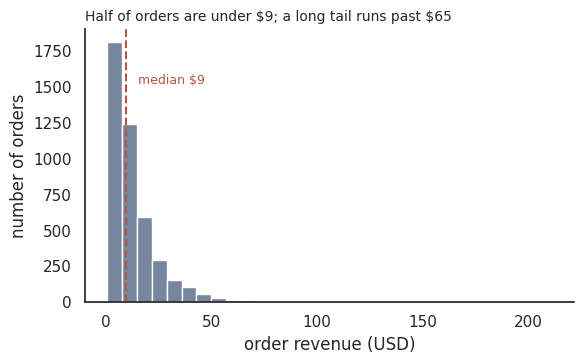

In [5]:
median = df['revenue'].median()
p99 = df['revenue'].quantile(0.99)

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.histplot(data=df, x='revenue', bins=30, color=BLUE, ax=ax)
ax.axvline(median, color=RUST, ls='--')
ax.text(median + 6, ax.get_ylim()[1] * 0.8, f'median ${median:.0f}', color=RUST, fontsize=9)
finish(ax, f'Half of orders are under ${median:.0f}; a long tail runs past ${p99:.0f}',
       xlabel='order revenue (USD)', ylabel='number of orders', fontsize=10)
plt.show()

**Caption:** The distribution of individual order revenue helps managers understand typical customer spending and make decisions about pricing and sales strategies.

The histogram is right-skewed, showing that most orders generate relatively low revenue, while a small number of orders generate much higher revenue. Unlike category totals, which only show the overall revenue for each category, the histogram shows how individual order revenues are distributed.

**Code Explanation:** First, I calculated the median and 99th percentile for the `revenue` column in the `df` DataFrame and stored the results in `median` and `p99`. Second, I created a histogram using Seaborn with 30 bins to show the distribution of individual order revenue. Third, I added a vertical dashed line in rust color using `ax.axvline()` to mark the median and used `ax.text()` to display the median value next to the line. Finally, I used `finish()` to add a title highlighting the median and the long right tail of the distribution, along with labels for both axes.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

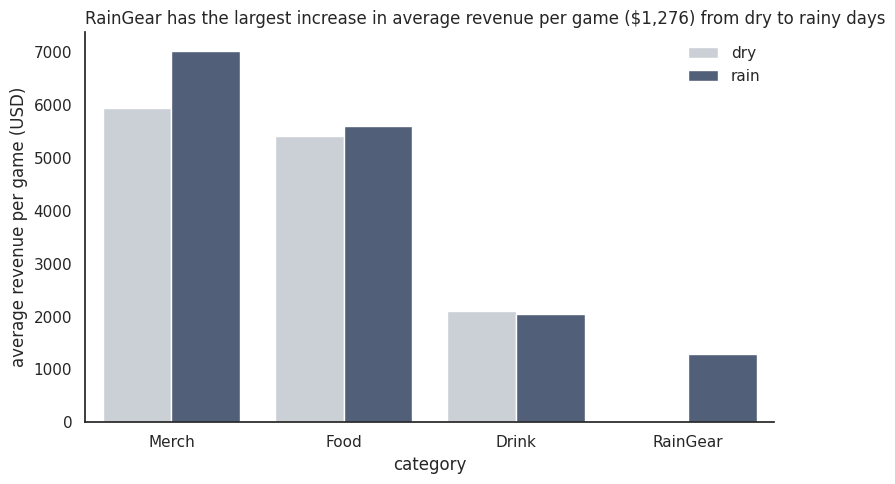

In [6]:
# Calculate average revenue per game by weather and category
per_game = (df.groupby(['weather', 'category'])['revenue'].sum().unstack(0)
              .div(df.groupby('weather')['game'].nunique(), axis='columns'))

# Find the largest increase from dry to rainy days
increase = per_game['rain'] - per_game['dry']
max_increase = increase.max()
max_category = increase.idxmax()

revenue_long = per_game.reset_index().melt(id_vars='category', var_name='weather', value_name='revenue_per_game')
order = per_game['dry'].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=revenue_long, x='category', y='revenue_per_game', hue='weather', order=order,
            palette={'dry': GRAY, 'rain': BLUE}, ax=ax)
ax.legend(title=None, frameon=False)
finish(ax, f'{max_category} has the largest increase in average revenue per game (${max_increase:,.0f}) from dry to rainy days',
       xlabel='category', ylabel='average revenue per game (USD)')

plt.show()

**Caption:** Comparing average revenue per game on dry and rainy days helps managers decide which product categories to prioritize when planning inventory and distribution under different weather conditions.

The grouped bar chart shows how average revenue per game differs across categories between dry and rainy days. I used average revenue per game to make a fair comparison between weather conditions by accounting for differences in the number of dry and rainy games.

**Code Explanation:** First, I grouped the `df` DataFrame by `weather` and `category`, calculated the total revenue using `.sum()`, and divided it by the number of unique games under each weather condition to calculate the average revenue per game. I stored the result in `per_game`. Second, I calculated the difference in average revenue per game between rainy and dry days for each category and used `.max()` and `.idxmax()` to find the largest increase and which category had it. Third, I used `.reset_index()` and `.melt()` to convert the data into a long format and sorted the categories by average revenue on dry days in descending order. Fourth, I created a grouped bar chart using Seaborn to compare average revenue per game across categories on dry and rainy days. I also added a legend to show the two weather conditions. Finally, I used `finish()` to add a title highlighting the category with the largest increase and its dollar amount, along with labels for both axes.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) No chart changed my mind about the data. Chart 4 was the hardest to title because the histogram shows the overall distribution of individual order revenue, making it difficult to identify a single key finding with a specific numerical value. So, instead of just describing the shape of the distribution, I calculated the median and 99th percentile to highlight the typical order revenue and high order values in the title.

b) If a manager wants to understand which zone generates the most total revenue, then the left panel is the right one to show. If a manager wants to compare sales performance across zones by accounting for differences in zone capacity and see which zone generates the highest revenue relative to its capacity, then the right panel is the better choice.